# 04 - Modelo 2: Tipo de Ataque

Segunda etapa do IDS: recebe os fluxos que o modelo binario marcou como ataque e diz qual e o ataque
(DDoS, PortScan, WebAttack ou SQLInjection).

- Treinado **so com fluxos de ataque**.
- Desequilibrio tratado com **pesos por classe** (`balanced`) no treino; o teste nao e alterado.
- SQLInjection tem pouquissimos exemplos (2 no teste), entao a avaliacao principal e por
  **validacao cruzada com 5 folds**, que avalia todos os exemplos de treino.
- Quando a confianca do modelo e baixa, o ataque vira **Desconhecido** em vez de receber um tipo errado.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

from src.data import build_dataset, train_test, split_xy
from src.features import make_model, sample_weights, shap_importance, stratified_sample, XGB_PARAMS
from src.pipeline import MODELS_DIR, save_model

PARAMS = dict(n_estimators=300)

## 2. Dados e features

In [2]:
with open(MODELS_DIR / 'selecao_features_tipo_ataque.json', encoding='utf-8') as f:
    features = json.load(f)['features']

df = build_dataset()
train, test = train_test(df)
train, test = train[train['is_attack'] == 1], test[test['is_attack'] == 1]

X_train, _, tipo_train = split_xy(train)
X_test, _, tipo_test = split_xy(test)
X_train, X_test = X_train[features], X_test[features]

le = LabelEncoder()
y_train = pd.Series(le.fit_transform(tipo_train), index=X_train.index)
y_test = pd.Series(le.transform(tipo_test), index=X_test.index)
classes = list(le.classes_)

print(f'{len(features)} features | classes: {classes}')
pd.DataFrame({'treino': tipo_train.value_counts(), 'teste': tipo_test.value_counts()})

3 features | classes: ['DDoS', 'PortScan', 'SQLInjection', 'WebAttack']


,treino,teste
attack_type,,
DDoS,102393,25598
WebAttack,1596,399
PortScan,1535,384
SQLInjection,10,3


## 3. Validacao cruzada (5 folds)

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = np.zeros((len(y_train), len(classes)))
for tr, va in skf.split(X_train, y_train):
    modelo = make_model(len(classes), **PARAMS)
    modelo.fit(X_train.iloc[tr], y_train.iloc[tr],
               sample_weight=sample_weights(y_train.iloc[tr], balanced=True))
    oof[va] = modelo.predict_proba(X_train.iloc[va])

oof_pred = oof.argmax(axis=1)
print(classification_report(y_train, oof_pred, target_names=classes, digits=4))

              precision    recall  f1-score   support

        DDoS     1.0000    0.9998    0.9999    102393
    PortScan     0.9774    0.9876    0.9825      1535
SQLInjection     1.0000    0.8000    0.8889        10
   WebAttack     0.9869    0.9887    0.9878      1596

    accuracy                         0.9995    105534
   macro avg     0.9911    0.9440    0.9648    105534
weighted avg     0.9995    0.9995    0.9995    105534



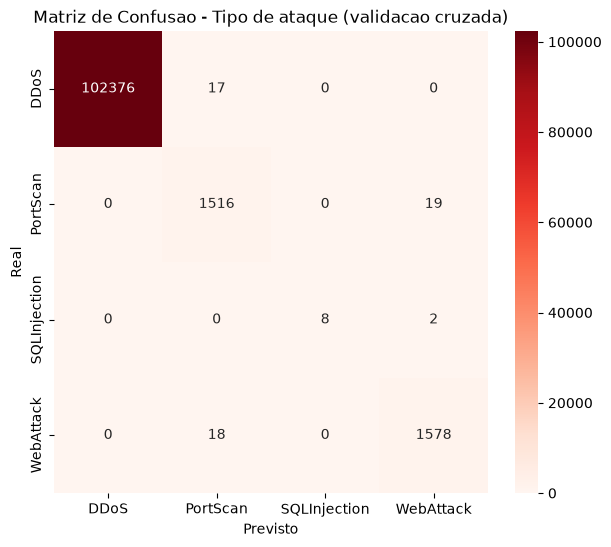

In [4]:
def plot_cm(y_true, y_pred, labels, titulo):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels, yticklabels=labels)
    plt.title(titulo)
    plt.ylabel('Real')
    plt.xlabel('Previsto')
    plt.show()


plot_cm(le.inverse_transform(y_train), le.inverse_transform(oof_pred), classes,
        'Matriz de Confusao - Tipo de ataque (validacao cruzada)')

## 4. Limiar de confianca ("Desconhecido")

A confianca e a maior probabilidade entre as classes. Previsoes com confianca abaixo do limiar viram
*Desconhecido*. Para cada limiar candidato, conta quantos **erros** da validacao cruzada viram
Desconhecido (bom) e quantos **acertos** viram Desconhecido (ruim); o limiar escolhido maximiza a
diferenca. Em empate, fica o maior limiar.

,limiar,erros_pegos,acertos_perdidos,saldo
0,0.50,0,1,-1
1,0.55,4,8,-4
2,0.60,6,10,-4
3,0.65,8,11,-3
4,0.70,10,15,-5
5,0.75,12,17,-5
6,0.80,13,29,-16
7,0.85,14,31,-17
8,0.90,14,50,-36
9,0.95,14,202,-188


Limiar de confianca: 0.5000
Acertos que viram Desconhecido: 1 de 105478
Erros que viram Desconhecido:   0 de 56


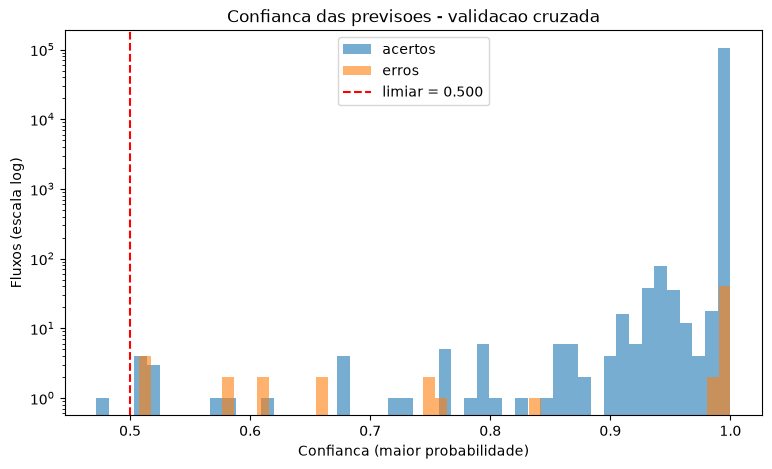

In [5]:
confianca = oof.max(axis=1)
acertou = oof_pred == y_train.values

candidatos = pd.DataFrame({'limiar': np.round(np.arange(0.5, 1.0, 0.05), 2).tolist() + [0.99]})
candidatos['erros_pegos'] = [int((~acertou & (confianca < t)).sum()) for t in candidatos['limiar']]
candidatos['acertos_perdidos'] = [int((acertou & (confianca < t)).sum()) for t in candidatos['limiar']]
candidatos['saldo'] = candidatos['erros_pegos'] - candidatos['acertos_perdidos']
melhor = candidatos[candidatos['saldo'] == candidatos['saldo'].max()]
threshold = float(melhor['limiar'].max())
display(candidatos)

print(f'Limiar de confianca: {threshold:.4f}')
print(f'Acertos que viram Desconhecido: {(confianca[acertou] < threshold).sum()} de {acertou.sum()}')
print(f'Erros que viram Desconhecido:   {(confianca[~acertou] < threshold).sum()} de {(~acertou).sum()}')

plt.figure(figsize=(9, 5))
plt.hist(confianca[acertou], bins=50, alpha=0.6, label='acertos', log=True)
plt.hist(confianca[~acertou], bins=50, alpha=0.6, label='erros', log=True)
plt.axvline(threshold, color='red', linestyle='--', label=f'limiar = {threshold:.3f}')
plt.xlabel('Confianca (maior probabilidade)')
plt.ylabel('Fluxos (escala log)')
plt.title('Confianca das previsoes - validacao cruzada')
plt.legend()
plt.show()

## 5. Treino final e avaliacao no teste

              precision    recall  f1-score   support

        DDoS     1.0000    0.9997    0.9999     25598
    PortScan     0.9744    0.9896    0.9819       384
SQLInjection     1.0000    1.0000    1.0000         3
   WebAttack     0.9900    0.9925    0.9912       399

    accuracy                         0.9995     26384
   macro avg     0.9911    0.9954    0.9933     26384
weighted avg     0.9995    0.9995    0.9995     26384



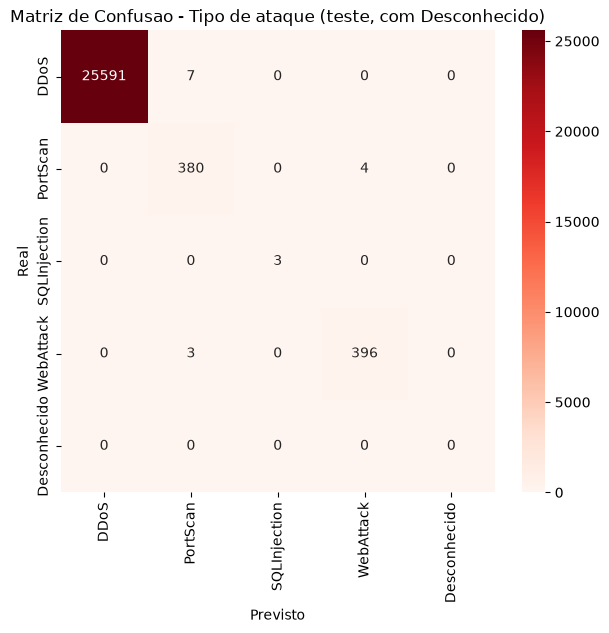

In [6]:
modelo = make_model(len(classes), **PARAMS)
modelo.fit(X_train, y_train, sample_weight=sample_weights(y_train, balanced=True))

proba_test = modelo.predict_proba(X_test)
pred_test = proba_test.argmax(axis=1)
print(classification_report(y_test, pred_test, labels=range(len(classes)),
                            target_names=classes, digits=4, zero_division=0))

pred_nome = np.where(proba_test.max(axis=1) >= threshold, le.inverse_transform(pred_test), 'Desconhecido')
plot_cm(tipo_test, pred_nome, classes + ['Desconhecido'],
        'Matriz de Confusao - Tipo de ataque (teste, com Desconhecido)')

## 6. Importancia final (SHAP)

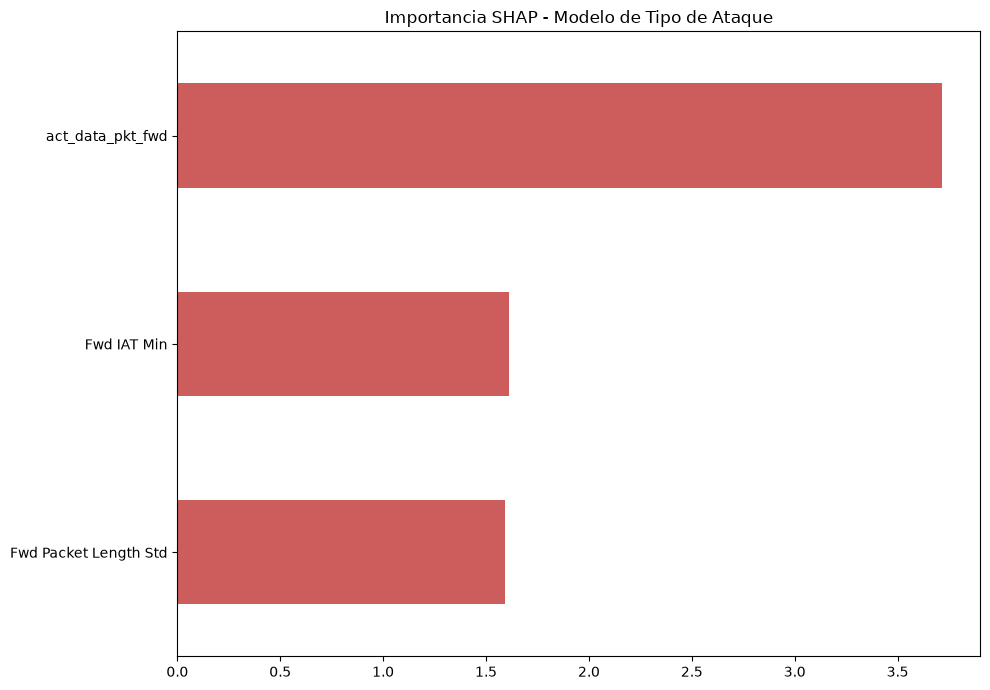

In [7]:
X_amostra, _ = stratified_sample(X_test, y_test, 5000)
shap_final = shap_importance(modelo, X_amostra)

plt.figure(figsize=(10, 7))
shap_final[::-1].plot.barh(color='indianred')
plt.title('Importancia SHAP - Modelo de Tipo de Ataque')
plt.tight_layout()
plt.show()

## 7. Salvar modelo

In [8]:
report_cv = classification_report(y_train, oof_pred, target_names=classes, output_dict=True)
metadata = {
    'features': features,
    'threshold': threshold,
    'classes': classes,
    'xgb_params': {**XGB_PARAMS, **PARAMS, 'sample_weight': 'balanced'},
    'metricas_cv': {
        'f1_macro': round(report_cv['macro avg']['f1-score'], 6),
        'f1_por_classe': {c: round(report_cv[c]['f1-score'], 6) for c in classes},
    },
}
save_model(modelo, 'modelo_tipo_ataque', metadata)
print(json.dumps(metadata['metricas_cv'], indent=2))

{
  "f1_macro": 0.964775,
  "f1_por_classe": {
    "DDoS": 0.999917,
    "PortScan": 0.982502,
    "SQLInjection": 0.888889,
    "WebAttack": 0.987793
  }
}
